# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 2**20

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)   # (x, y, z)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512     # rays (x-z pixels) * samples per ray (Ny)
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_  The coronal and sagittal views would look squashed or stretched along z, because a voxel is 1 mm tall but only 0.5 mm wide.
Distances and sizes measured on screen would be wrong, so tumour dimensions would be unreliable.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

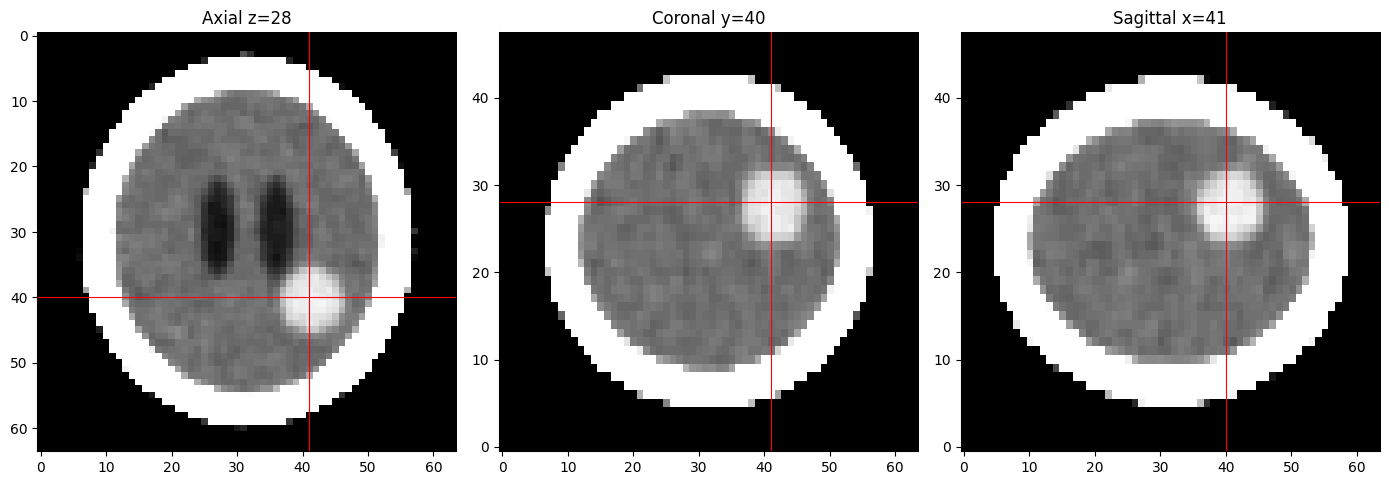

centroid (28,40,41) | error vs truth: 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: soft-tissue HU range, restricted to the brain interior
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: largest connected component and its centroid
lab, n = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lab, range(1, n + 1))
lesion = lab == (np.argmax(sizes) + 1)
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]

# TODO 3: three-plane view with cross-hairs
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
W, L = 80, 40
axes[0].imshow(window(vol[cz], W, L), cmap="gray")
axes[0].axvline(cx, c="r", lw=.8); axes[0].axhline(cy, c="r", lw=.8)
axes[0].set_title(f"Axial z={cz}")

axes[1].imshow(window(vol[:, cy, :], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axvline(cx, c="r", lw=.8); axes[1].axhline(cz, c="r", lw=.8)
axes[1].set_title(f"Coronal y={cy}")

axes[2].imshow(window(vol[:, :, cx], W, L), cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axvline(cy, c="r", lw=.8); axes[2].axhline(cz, c="r", lw=.8)
axes[2].set_title(f"Sagittal x={cx}")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
t = np.array(ndimage.center_of_mass(labels == 5))
err_mm = np.linalg.norm((np.array([cz, cy, cx]) - t) * SPACING)
print(f"centroid ({cz},{cy},{cx}) | error vs truth: {err_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_  Partial-volume effect: voxels at the skull/brain boundary average bone (high HU) and brain, so they land in the tumour’s 55–90 HU range.
Overlapping ranges: intensity alone cannot separate “tumour” from “boundary blend” (Slide 28).
Erosion: it removes that thin shell, leaving only true interior voxels.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


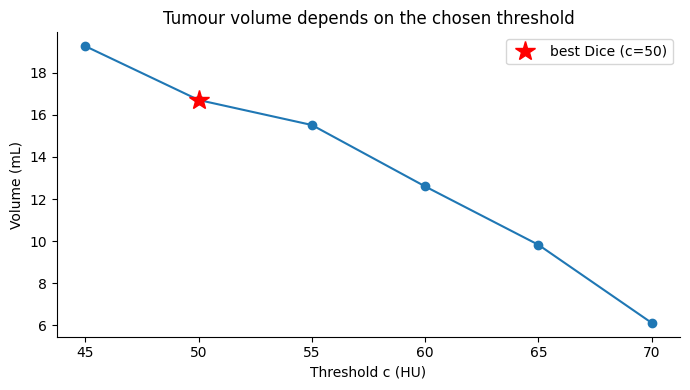

Report volume range: 6.1 – 19.3 mL


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    lab_c, _ = ndimage.label(vol > c)
    region = lab_c == lab_c[cz, cy, cx]          # component containing the lesion centre
    vox = int(region.sum())
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold": c, "voxels": vox,
                 "volume_ml": vox * VOXEL_MM3 / 1000, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table.threshold, table.volume_ml, "o-")
best = table.loc[table.dice.idxmax()]
ax.plot(best.threshold, best.volume_ml, "r*", ms=15, label=f"best Dice (c={best.threshold:.0f})")
ax.set_xlabel("Threshold c (HU)"); ax.set_ylabel("Volume (mL)")
ax.set_title("Tumour volume depends on the chosen threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Report volume range: {table.volume_ml.min():.1f} – {table.volume_ml.max():.1f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_  Choose c: put it midway between the tumour’s and the brain’s mean HU (the half-maximum boundary), and check it against the visible edge on the slices.
Show uncertainty: report the volume as a range and overlay several threshold contours (e.g. 50/60/70) on the slices, so the surgeon sees the boundary as a band rather than one exact line.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

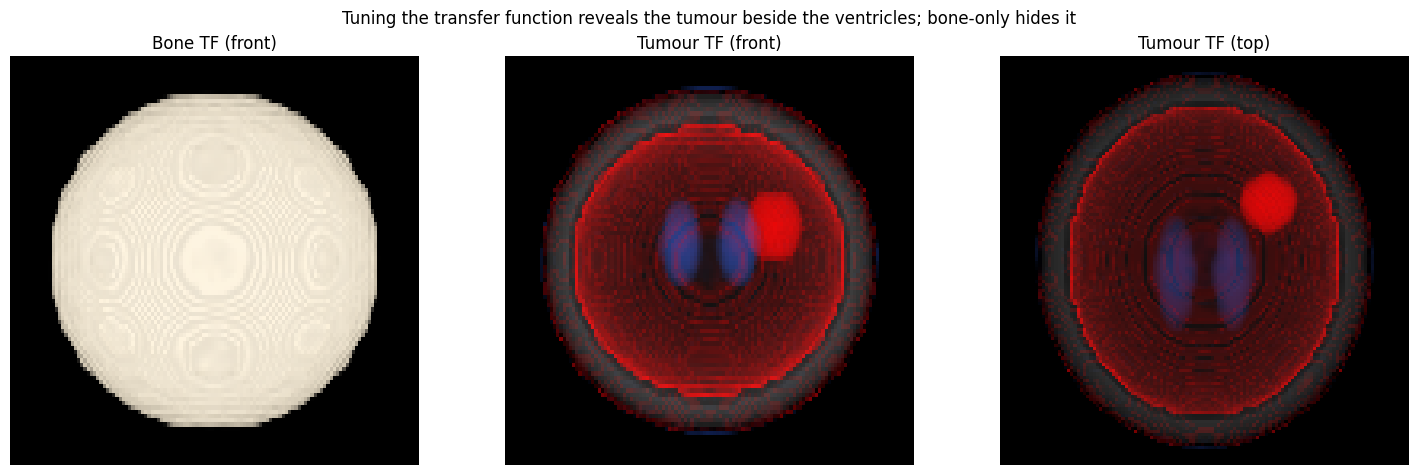

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (0,     (0, 0, 0), 0),          # air / scalp transparent
    (5,     (0.2, 0.4, 1), 0.02),   # CSF: blue, faint
    (20,    (0.2, 0.4, 1), 0.02),
    (30,    (0, 0, 0), 0),          # brain tissue transparent
    (50,    (0, 0, 0), 0),
    (60,    (1, 0, 0), 0.1),        # tumour: red
    (90,    (1, 0, 0), 0.1),
    (110,   (0, 0, 0), 0),
    (300,   (0, 0, 0), 0),
    (400,   (1, 1, 1), 0.005),      # bone: almost transparent
    (1500,  (1, 1, 1), 0.005),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C, _ = render(vol, bone_tf, axis=1)
axes[0].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT); axes[0].set_title("Bone TF (front)")

C, _ = render(vol, tumour_tf, axis=1)
axes[1].imshow(np.clip(C, 0, 1), origin="lower", aspect=ASPECT); axes[1].set_title("Tumour TF (front)")

C, _ = render(vol, tumour_tf, axis=0)
axes[2].imshow(np.clip(C, 0, 1), origin="lower"); axes[2].set_title("Tumour TF (top)")

for a in axes: a.axis("off")

# TODO 4: suptitle
fig.suptitle("Tuning the transfer function reveals the tumour beside the ventricles; bone-only hides it")
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_  Cause: the faint red rim comes from partial-volume voxels at the skull boundary, whose HU values fall in the tumour range. That is the “overlapping intensity ranges / no unique mapping from HU to material” challenge.
Fix: use segmentation or masking (Slides 31–32), here by removing everything outside the brain mask, or clipping or cutting planes.
Why a transfer function can’t: a TF depends only on intensity, so it cannot distinguish a true tumour voxel from a boundary voxel with the same HU.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_  The lesion sits in the right-posterior part of the brain at voxel (z=28, y=40, x=41), lateral to the ventricles, and is clearly separate from them. Its volume is roughly 6-19 mL depending on the threshold used, with the best-agreeing segmentation (c = 50 HU) giving about 16.7 mL, so the figure should be read as a range and not an exact number. I recommend opening with the three-plane MPR, because slicing exposes internal structure that the 3-D render occludes, and the lesion’s position and extent can be confirmed in all planes at once. The segmentation overlay should follow, since segmentation is what allows the volume to be measured. The 3-D render is best kept as a final orientation aid. Its limitation is that the transfer function maps intensity alone to colour and opacity, so overlapping intensities (such as partial-volume voxels at the skull boundary) can show up as false structure, and the apparent edges in the render should not be treated as exact anatomy.